# Pipeline Results and Conclusions

This notebook compares the three end-to-end pipelines in `5_Models/5_03_Pipeline_Evaluation` on the **test** split.
Each pipeline writes one metrics CSV to `results/`; this notebook loads every `pipeline_*.csv` so all models are
compared on the same impressions and cutoffs.

| Model | Candidate generator | Reranker |
|---|---|---|
| Attention reranker | Niche two-tower (200 popularity + 250 niche) | `RR_4` + metadata, `softmax+lambda_ndcg` |
| Popularity reranker | Combined (200 popularity + 250 content) | Causal smoothed prior article CTR |
| Content-similarity reranker | Combined (200 popularity + 250 content) | Content text/entity cosine fusion (`text 0.50`) |

All metrics are known-click metrics. Unshown retrieved articles have unknown relevance, so every score here is a
lower bound on true quality, and clicks the retriever missed stay in the denominator as misses.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path('../../results')

MODEL_LABELS = {
    'attention_reranker': 'Attention reranker (niche CG + RR4)',
    'popularity_smoothed_prior_article_ctr': 'Popularity reranker (combined CG)',
    'content_fusion_text_0.50': 'Content-similarity reranker (combined CG)',
}

ACCURACY_METRICS = ['ndcg', 'mrr', 'recall_pooled', 'recall_impression_mean', 'hit_rate']
REACH_METRICS = ['long_tail_recall', 'cold_article_recall', 'novelty_bits', 'catalogue_coverage', 'personalisation']

result_files = sorted(RESULTS.glob('pipeline_*.csv'))
if not result_files:
    raise FileNotFoundError(f'No pipeline result CSVs found under {RESULTS.resolve()}')

results = pd.concat([pd.read_csv(path) for path in result_files], ignore_index=True)
results['model_label'] = results['model'].map(MODEL_LABELS).fillna(results['model'])
results['k'] = results['k'].astype(int)
results['impressions'] = results['impressions'].astype(int)
results['clicked_impressions'] = results['clicked_impressions'].astype(int)

print('Loaded:')
for path in result_files:
    print(' -', path.name)
print()
print(f"{results['model'].nunique()} models | split(s): {sorted(results['split'].unique())} | k values: {sorted(int(v) for v in results['k'].unique())}")
print(f"Impressions per result: {sorted(int(v) for v in results['impressions'].unique())}")


Loaded:
 - pipeline_attention_reranker_niche_generated_test_all.csv
 - pipeline_baseline_content_popularity_combined_content_similarity_test_all.csv
 - pipeline_baseline_content_popularity_combined_popularity_reranker_test_all.csv

3 models | split(s): ['test'] | k values: [5, 10, 30]
Impressions per result: [30270]


## Accuracy at every cutoff

`ndcg`, `mrr`, `recall_pooled` and `hit_rate` measure whether the final list contains the clicks users actually made.
`recall_impression_mean` averages recall only over impressions that have at least one known click.


In [2]:
def metric_table(metrics):
    table = results.pivot(index='model_label', columns='k', values=metrics)
    table = table.reindex(columns=metrics, level=0)
    table.columns = [f'{metric}@{k}' for metric, k in table.columns]
    return table

accuracy_table = metric_table(ACCURACY_METRICS)
accuracy_table.round(4)


,ndcg@5,ndcg@10,ndcg@30,mrr@5,mrr@10,mrr@30,recall_pooled@5,recall_pooled@10,recall_pooled@30,recall_impression_mean@5,recall_impression_mean@10,recall_impression_mean@30,hit_rate@5,hit_rate@10,hit_rate@30
model_label,,,,,,,,,,,,,,,
Attention reranker (niche CG + RR4),0.1202,0.1482,0.1978,0.1212,0.1343,0.1465,0.1463,0.2227,0.4099,0.1675,0.2489,0.4415,0.2156,0.3151,0.5307
Content-similarity reranker (combined CG),0.0005,0.0008,0.0015,0.0004,0.0006,0.0009,0.0007,0.0016,0.0044,0.0009,0.0017,0.0046,0.0011,0.0025,0.0068
Popularity reranker (combined CG),0.0444,0.0604,0.1005,0.0428,0.0504,0.0614,0.0615,0.1015,0.2469,0.0709,0.1184,0.2773,0.0943,0.1534,0.3506


## Reach, diversity and personalisation

These metrics describe *what kind* of catalogue the final list covers rather than how many clicks it captures.
At `k = 30` the list is the full final Top-30 that the pipelines save.


In [3]:
reach_table = metric_table(REACH_METRICS)
reach_table.round(4)


,long_tail_recall@5,long_tail_recall@10,long_tail_recall@30,cold_article_recall@5,cold_article_recall@10,cold_article_recall@30,novelty_bits@5,novelty_bits@10,novelty_bits@30,catalogue_coverage@5,catalogue_coverage@10,catalogue_coverage@30,personalisation@5,personalisation@10,personalisation@30
model_label,,,,,,,,,,,,,,,
Attention reranker (niche CG + RR4),0.0085,0.0112,0.0199,0.0000,0.0000,0.0000,11.3377,11.5238,11.9259,0.0089,0.0138,0.0257,0.8398,0.8275,0.7831
Content-similarity reranker (combined CG),0.0005,0.0009,0.0021,0.0055,0.0055,0.0055,15.7042,15.7013,15.6997,0.2066,0.2952,0.4720,0.9879,0.9848,0.9771
Popularity reranker (combined CG),0.0002,0.0009,0.0032,0.0000,0.0000,0.0000,12.5651,12.6835,12.8501,0.0039,0.0095,0.0296,0.8088,0.7865,0.8073


In [4]:
display_columns = [
    'model_label', 'k', 'impressions', 'clicked_impressions',
    'ndcg', 'mrr', *REACH_METRICS,
]
tidy = results[display_columns].sort_values(['model_label', 'k']).reset_index(drop=True)
tidy.round(4)


,model_label,k,impressions,clicked_impressions,ndcg,mrr,long_tail_recall,cold_article_recall,novelty_bits,catalogue_coverage,personalisation
0,Attention reranker (niche CG + RR4),5,30270,30270,0.1202,0.1212,0.0085,0.0000,11.3377,0.0089,0.8398
1,Attention reranker (niche CG + RR4),10,30270,30270,0.1482,0.1343,0.0112,0.0000,11.5238,0.0138,0.8275
2,Attention reranker (niche CG + RR4),30,30270,30270,0.1978,0.1465,0.0199,0.0000,11.9259,0.0257,0.7831
3,Content-similarity reranker (combined CG),5,30270,30270,0.0005,0.0004,0.0005,0.0055,15.7042,0.2066,0.9879
4,Content-similarity reranker (combined CG),10,30270,30270,0.0008,0.0006,0.0009,0.0055,15.7013,0.2952,0.9848
5,Content-similarity reranker (combined CG),30,30270,30270,0.0015,0.0009,0.0021,0.0055,15.6997,0.4720,0.9771
6,Popularity reranker (combined CG),5,30270,30270,0.0444,0.0428,0.0002,0.0000,12.5651,0.0039,0.8088
7,Popularity reranker (combined CG),10,30270,30270,0.0604,0.0504,0.0009,0.0000,12.6835,0.0095,0.7865
8,Popularity reranker (combined CG),30,30270,30270,0.1005,0.0614,0.0032,0.0000,12.8501,0.0296,0.8073


## Accuracy versus cutoff

Every accuracy metric should rise with `k` (a longer list can only add hits). The vertical distance between the
lines is the end-to-end quality gap between pipelines.


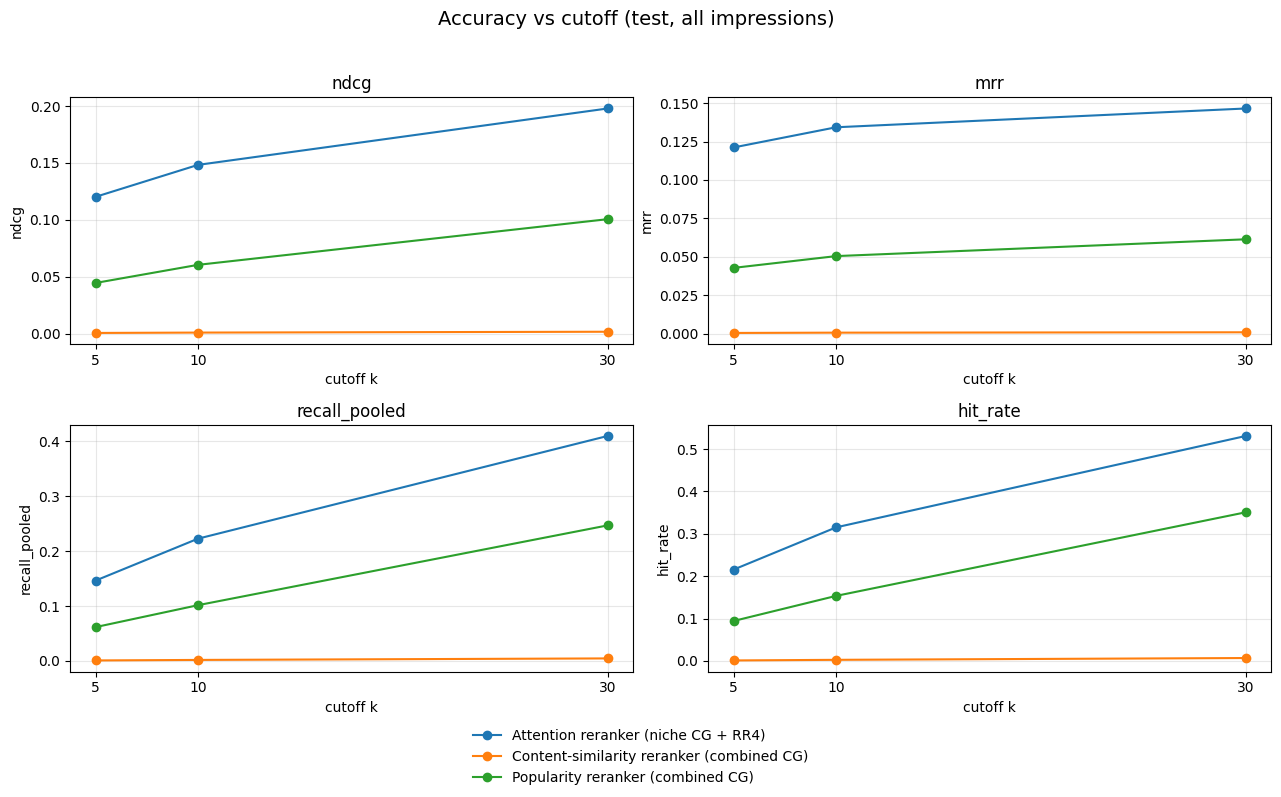

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, metric in zip(axes.ravel(), ['ndcg', 'mrr', 'recall_pooled', 'hit_rate']):
    for label, group in results.groupby('model_label'):
        group = group.sort_values('k')
        ax.plot(group['k'], group[metric], marker='o', label=label)
    ax.set_title(metric)
    ax.set_xlabel('cutoff k')
    ax.set_ylabel(metric)
    ax.set_xticks(sorted(results['k'].unique()))
    ax.grid(True, alpha=0.3)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=1, frameon=False)
fig.suptitle('Accuracy vs cutoff (test, all impressions)', fontsize=14)
fig.tight_layout(rect=(0, 0.08, 1, 0.96))
plt.show()


## Reach and diversity of the final list

Scores on a 0-1 scale are grouped below; `novelty_bits` is plotted separately because it uses a different scale.


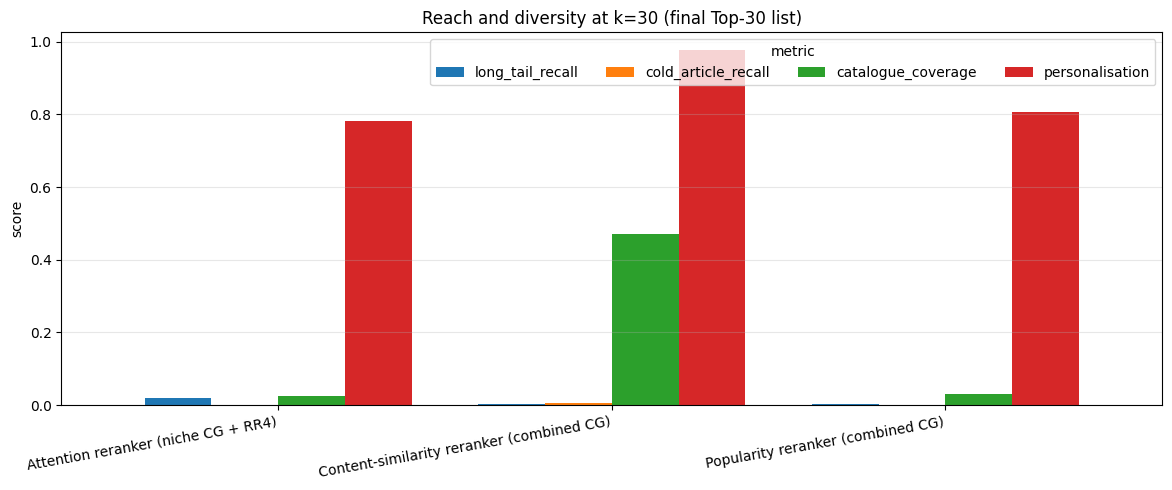

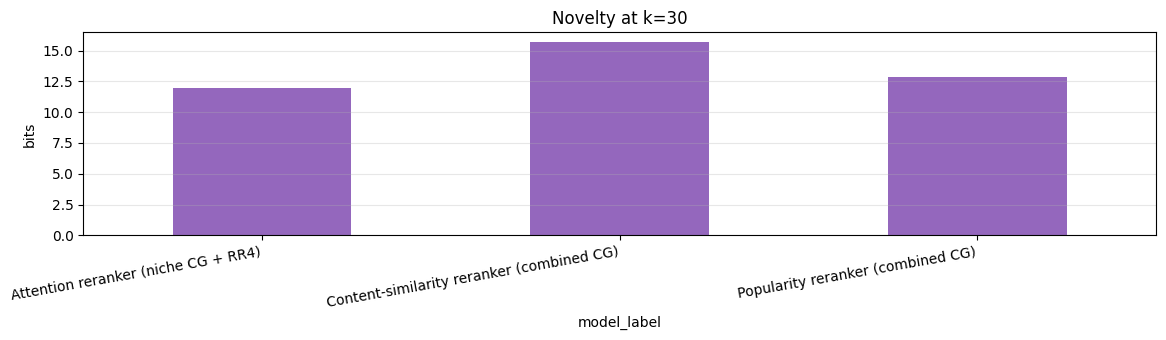

In [6]:
final_k = int(results['k'].max())
final = results[results['k'] == final_k].set_index('model_label')

bar_metrics = ['long_tail_recall', 'cold_article_recall', 'catalogue_coverage', 'personalisation']
fig, ax = plt.subplots(figsize=(12, 5))
final[bar_metrics].plot(kind='bar', ax=ax, width=0.8)
ax.set_title(f'Reach and diversity at k={final_k} (final Top-{final_k} list)')
ax.set_ylabel('score')
ax.set_xlabel('')
ax.grid(True, axis='y', alpha=0.3)
ax.legend(title='metric', ncol=4)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3.5))
final['novelty_bits'].plot(kind='bar', ax=ax, color='tab:purple')
ax.set_title(f'Novelty at k={final_k}')
ax.set_ylabel('bits')
ax.grid(True, axis='y', alpha=0.3)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()


## What the comparison shows

**Accuracy: the attention reranker wins decisively.** At `k = 10` it reaches nDCG@10 **0.148** and MRR@10 **0.134**,
about **2.5x** the popularity reranker (0.060 / 0.050) and roughly **180x** the content-similarity reranker
(0.0008 / 0.0006). The ordering is identical at `k = 5, 10, 30`, and the same pattern holds for pooled recall and
hit rate (0.315 vs 0.153 vs 0.003 at `k = 10`).

**The two baselines share a candidate generator, so their gap isolates the reranker.** On exactly the same 450
candidates per request, the causal smoothed-CTR rule beats the content-similarity rule by roughly **75x on nDCG@10**
and **60x on pooled recall**. The content-similarity reranker is effectively broken as a ranker: its high catalogue
coverage (0.295 at `k = 10`) and novelty (15.70 bits) are artefacts of scattering near-random Top-K lists across the
catalogue, not evidence of useful personalisation.

**Reach trades off against accuracy.** The attention reranker wins by concentrating on a small set of safe, likely-
clicked articles, so it has the lowest novelty (11.52 bits at `k = 10`) and catalogue coverage (~0.014). The
popularity reranker behaves the same way (coverage 0.0095, novelty 12.68) but is far less accurate. Only the content
baseline reaches broad coverage (0.295-0.472), and it pays for that with near-zero relevance.

**Long-tail and cold reach remain weak everywhere.** Long-tail recall peaks at 0.020 (attention, `k = 30`) and 0.003
(popularity); cold-article recall is 0 for both the popularity and attention pipelines, and the content baseline is
the only one with non-zero cold recall (0.0055) - again at the cost of accuracy. The niche branch that helped
candidate generation in `5_01_Candidate_Generation` is not yet converting into cold/long-tail precision after
reranking.

**Bottom line.** The learned attention reranker is the best pipeline on every accuracy metric and is the recommended
system. The popularity rule is a strong, cheap fallback; the content-similarity rule should not be used as a
reranker.
